# theSpot: Hotspot Clustering of Arlington Venues

**Goal:** identify dense clusters of trending venues in Arlington, VA, so the app knows where its map is dense enough to launch and where it is too sparse.

**Method:** DBSCAN with the haversine metric on latitude/longitude. DBSCAN suits this problem because it needs no preset cluster count and it labels isolated venues as noise instead of forcing them into a cluster.

**Data:** 15 hand-curated venues (`data/spots.csv`). Coordinates were verified against Google Maps or OpenStreetMap; the source for each venue is in the `coord_source` column.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

df = pd.read_csv("data/spots.csv")
print(df.shape)
df[["name", "category", "neighborhood", "lat", "lon"]].head(16)

(15, 8)


,name,category,neighborhood,lat,lon
0,Roggenart European Bakery,Bakery,Ballston,38.880623,-77.113365
1,For Five Coffee Roasters,Cafe,Rosslyn,38.896073,-77.070561
2,Ambar,Restaurant,Clarendon,38.888745,-77.093424
3,Hawkers,Restaurant,Ballston,38.880320,-77.110621
4,Inca Social,Restaurant,Rosslyn,38.893944,-77.078144
5,Skydome Restaurant,Restaurant,Crystal City,38.864045,-77.052800
6,Chiko,Restaurant,Shirlington,38.840534,-77.088028
7,Ruthie's All-Day,Restaurant,South Arlington,38.867320,-77.095278
8,Yume Sushi,Restaurant,East Falls Church,38.886444,-77.162285
9,Brooklyn Bagel Bakery,Bakery,Courthouse,38.891857,-77.084322


## 1. Cluster with DBSCAN (haversine)

`eps` is a walking-scale radius. With the haversine metric, scikit-learn expects radians, so the distance in km is divided by Earth's radius (6371 km).

In [2]:
EARTH_RADIUS_KM = 6371.0
coords = np.radians(df[["lat", "lon"]].to_numpy())

def run_dbscan(eps_km, min_samples):
    model = DBSCAN(eps=eps_km / EARTH_RADIUS_KM, min_samples=min_samples,
                   metric="haversine", algorithm="ball_tree")
    return model.fit_predict(coords)

df["cluster"] = run_dbscan(eps_km=0.8, min_samples=3)
n_clusters = df.loc[df.cluster >= 0, "cluster"].nunique()
n_noise = (df.cluster == -1).sum()
print(f"clusters: {n_clusters} | noise (isolated venues): {n_noise} of {len(df)}")
df.groupby("cluster")[["name"]].agg(list)

clusters: 2 | noise (isolated venues): 4 of 15


,name
cluster,
-1,"[Skydome Restaurant, Chiko, Ruthie's All-Day, ..."
0,"[Roggenart European Bakery, Hawkers, MidnighTr..."
1,"[For Five Coffee Roasters, Ambar, Inca Social,..."


## 2. Sensitivity check

The cluster count depends on `eps`, so here is how the result changes across reasonable walking distances. A result that holds across a range is more trustworthy than one tuned to a single value.

In [3]:
rows = []
for eps in [0.3, 0.5, 0.8, 1.2, 2.0]:
    labels = run_dbscan(eps, 3)
    k = len(set(labels)) - (1 if -1 in labels else 0)
    clustered = (labels != -1).sum()
    rows.append({"eps_km": eps, "clusters": k, "venues_clustered": clustered,
                 "noise": (labels == -1).sum()})
pd.DataFrame(rows)

,eps_km,clusters,venues_clustered,noise
0,0.3,2,7,8
1,0.5,2,7,8
2,0.8,2,11,4
3,1.2,2,11,4
4,2.0,1,12,3


## 3. Map the clusters

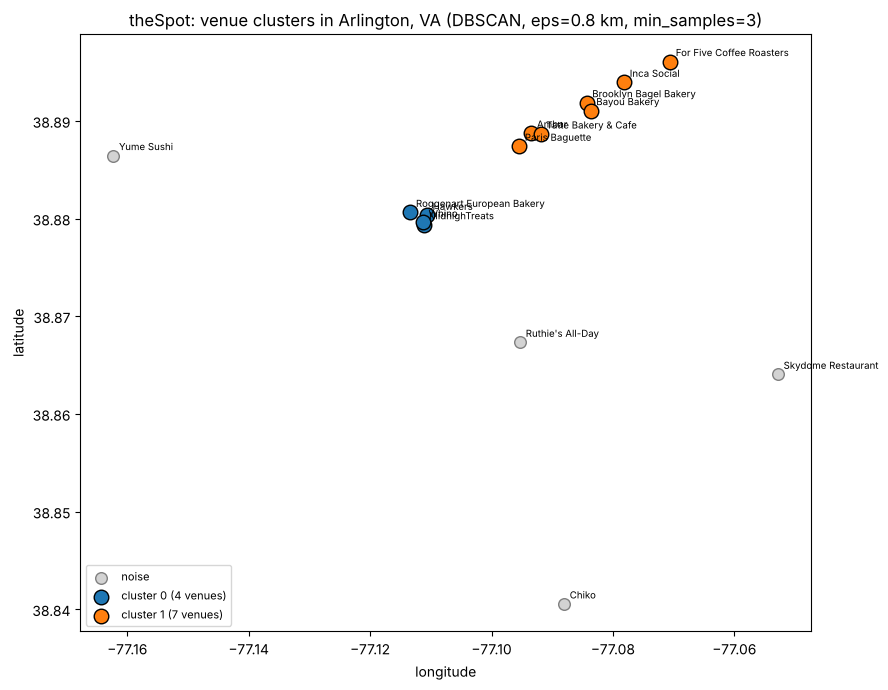

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))
palette = plt.cm.tab10.colors
for label in sorted(df.cluster.unique()):
    sub = df[df.cluster == label]
    if label == -1:
        ax.scatter(sub.lon, sub.lat, c="lightgray", edgecolor="gray", s=70, label="noise")
    else:
        ax.scatter(sub.lon, sub.lat, color=palette[label % 10], s=110,
                   edgecolor="black", label=f"cluster {label} ({len(sub)} venues)")
for _, r in df.iterrows():
    ax.annotate(r["name"], (r.lon, r.lat), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("theSpot: venue clusters in Arlington, VA (DBSCAN, eps=0.8 km, min_samples=3)")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("clusters.png", dpi=150)
plt.show()

## 4. Findings

- At eps = 0.8 km and min_samples = 3, DBSCAN found **2 clusters covering 11 of 15 venues**, with 4 venues labeled noise.
- **Cluster 1** (7 venues) spans Clarendon, Courthouse, and Rosslyn. **Cluster 0** (4 venues) is Ballston.
- The cluster count is 2 for every eps from 0.3 to 1.2 km, but coverage changes: 7 venues are clustered at 0.3 to 0.5 km and 11 at 0.8 to 1.2 km. At 2.0 km the two groups merge into a single cluster of 12 venues, so the Ballston and Clarendon/Courthouse/Rosslyn groups are distinct at walking scale.
- The four noise venues are Skydome (Crystal City), Chiko (Shirlington), Ruthie's All-Day (South Arlington), and Yume Sushi (East Falls Church). Those are the areas where a map would look sparse, so seeding should focus on the two dense groups first.
- **Caveats:** n = 15, and the venues were chosen by hand, so these clusters describe my seed list and not where Arlington's trending spots actually are. Coordinates were checked against Google Maps or OpenStreetMap (see `coord_source` in `data/spots.csv`), but For Five Coffee's location (Rosslyn) comes from OpenStreetMap only. The value of this step is the pipeline, which can be rerun on a larger dataset.

In [5]:
summary = (df[df.cluster >= 0].groupby("cluster")
           .agg(venues=("name", "count"),
                neighborhoods=("neighborhood", lambda s: ", ".join(sorted(set(s)))))
           .reset_index())
print(summary.to_string(index=False))
print("\nIsolated venues (noise):", ", ".join(df.loc[df.cluster == -1, "name"]))

 cluster  venues                  neighborhoods
       0       4                       Ballston
       1       7 Clarendon, Courthouse, Rosslyn

Isolated venues (noise): Skydome Restaurant, Chiko, Ruthie's All-Day, Yume Sushi
